1) Identify relationship between total advertising spend and sales?

2) Our next ad campaign will have a total spend of $200,000; how many units do we expect to sell as a result of this?

#### Importing required libraries

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

#### Reading our dataset

In [5]:
df = pd.read_csv("Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230100,37800,69200,22100
1,44500,39300,45100,10400
2,17200,45900,69300,9300
3,151500,41300,58500,18500
4,180800,10800,58400,12900


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   TV         200 non-null    int64
 1   radio      200 non-null    int64
 2   newspaper  200 non-null    int64
 3   sales      200 non-null    int64
dtypes: int64(4)
memory usage: 6.4 KB


#### Data cleaning

**Checking for duplicates**

In [9]:
df.duplicated().sum()

np.int64(0)

**Checking for null values**

In [10]:
df.isna().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

#### Exploratory Data Analysis

In [11]:
df.head()

,TV,radio,newspaper,sales
0,230100,37800,69200,22100
1,44500,39300,45100,10400
2,17200,45900,69300,9300
3,151500,41300,58500,18500
4,180800,10800,58400,12900


In [12]:
df.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147042.500000,23264.000000,30554.000000,14022.500000
std,85854.236315,14846.809176,21778.620839,5217.456566
min,700.000000,0.000000,300.000000,1600.000000
25%,74375.000000,9975.000000,12750.000000,10375.000000
50%,149750.000000,22900.000000,25750.000000,12900.000000
75%,218825.000000,36525.000000,45100.000000,17400.000000
max,296400.000000,49600.000000,114000.000000,27000.000000


In [20]:
df.dtypes

TV           int64
radio        int64
newspaper    int64
sales        int64
dtype: object

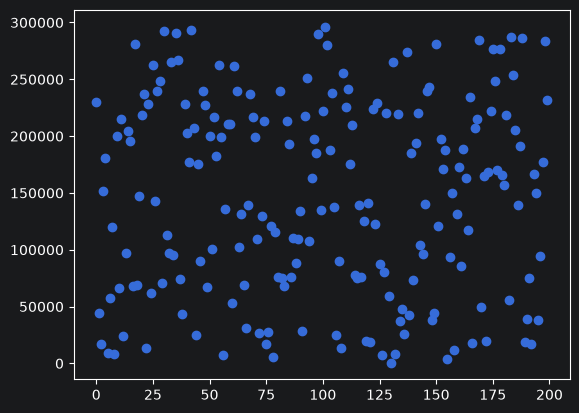

In [21]:
plt.scatter(x=df["TV"].index,y=df["TV"])

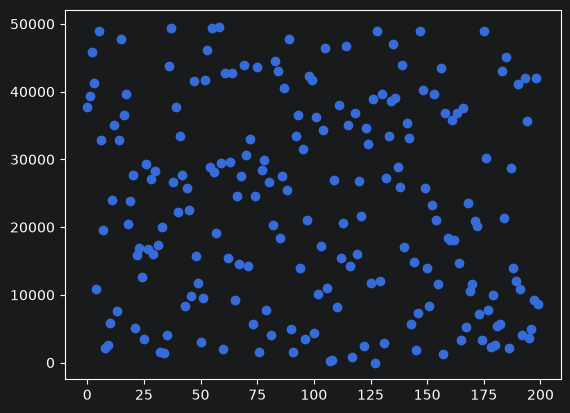

In [22]:
plt.scatter(x=df["radio"].index,y=df["radio"])

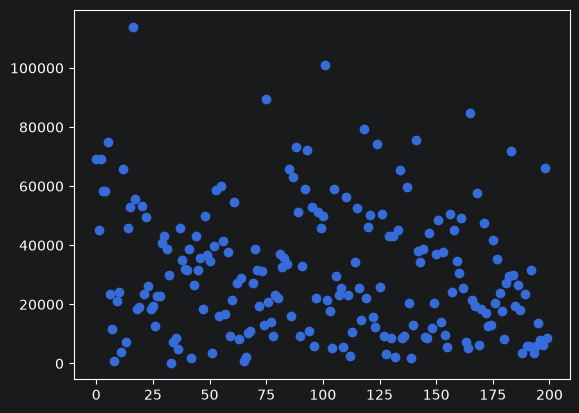

In [23]:
plt.scatter(x=df["newspaper"].index,y=df["newspaper"])

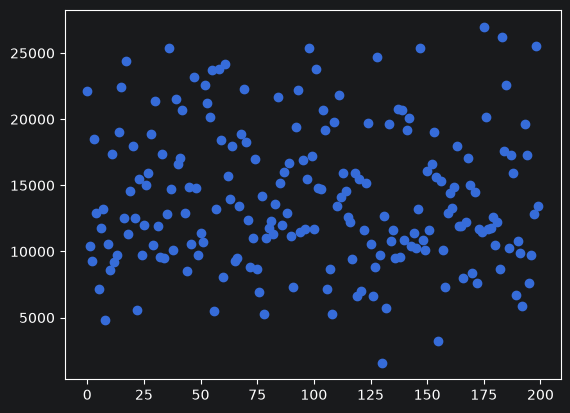

In [24]:
plt.scatter(x=df["sales"].index,y=df["sales"])

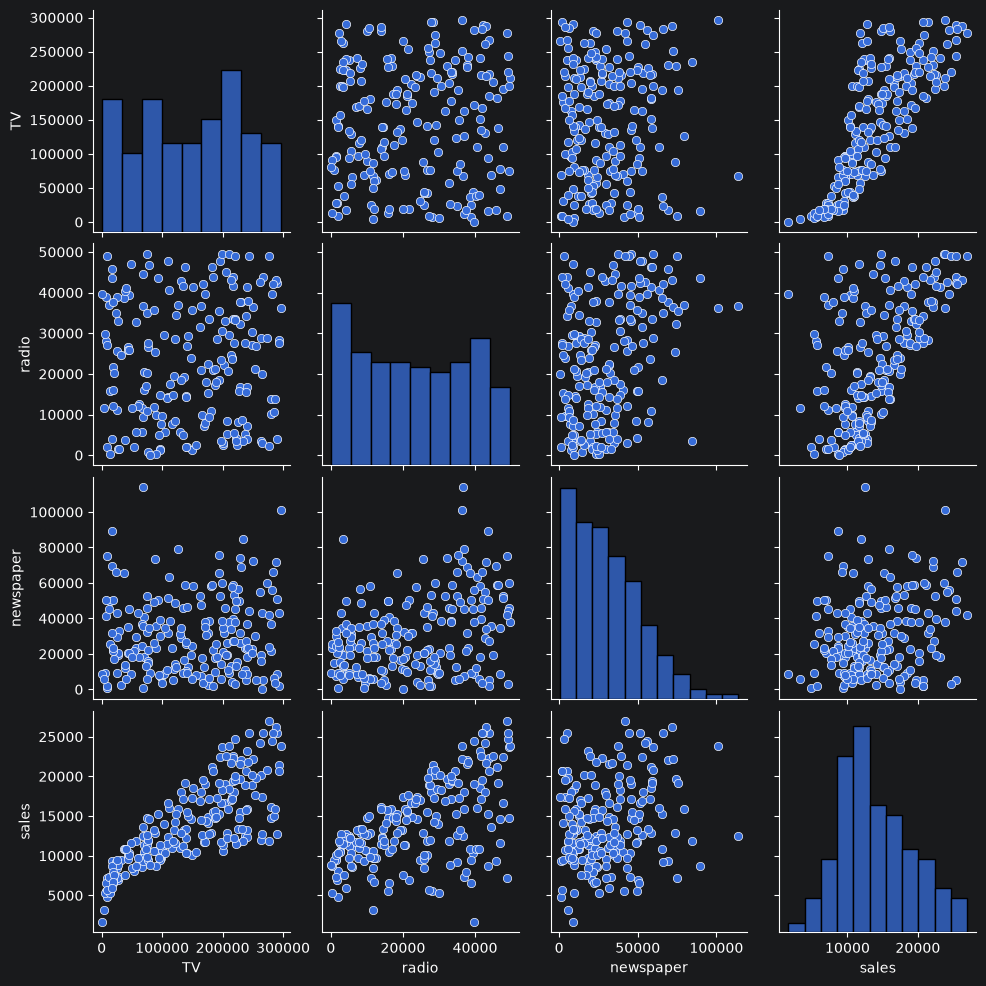

In [30]:
sns.pairplot(df)

In [42]:
help(plt.subplots_adjust)

Help on function subplots_adjust in module matplotlib.pyplot:

subplots_adjust(left: 'float | None' = None, bottom: 'float | None' = None, right: 'float | None' = None, top: 'float | None' = None, wspace: 'float | None' = None, hspace: 'float | None' = None) -> 'None'
    Adjust the subplot layout parameters.

    Unset parameters are left unmodified; initial values are given by
    :rc:`figure.subplot.[name]`.

    .. plot:: _embedded_plots/figure_subplots_adjust.py

    Parameters
    ----------
    left : float, optional
        The position of the left edge of the subplots,
        as a fraction of the figure width.
    right : float, optional
        The position of the right edge of the subplots,
        as a fraction of the figure width.
    bottom : float, optional
        The position of the bottom edge of the subplots,
        as a fraction of the figure height.
    top : float, optional
        The position of the top edge of the subplots,
        as a fraction of the figure

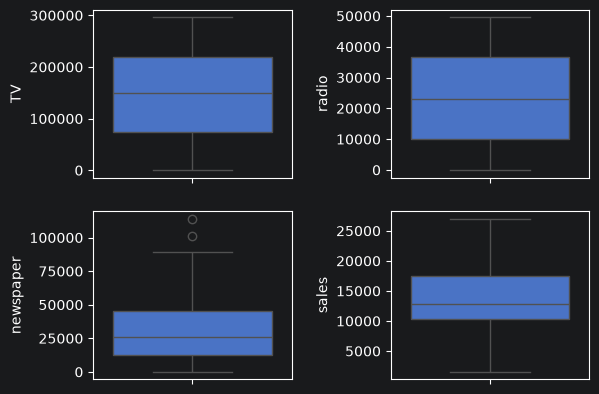

In [43]:
fig,ax = plt.subplots(nrows=2,ncols=2)
plt.subplots_adjust(wspace=0.5)
i = 0
j = 0
for k in df.columns:
    sns.boxplot(df[k],ax=ax[i,j])
    j += 1
    if j == 2:
        i += 1
        j = 0

In [59]:
lower_outlier_indices_dict = {}
upper_outlier_indices_dict = {}

def find_outlier_limits(df,k):
    q1 = df[k].quantile(0.25)
    q3 = df[k].quantile(0.75)
    iqr = q3 - q1
    left_limit = q1 - 1.5 * iqr
    right_limit = q3 + 1.5 * iqr
    return left_limit, right_limit

for k in df.columns:
    left_limit, right_limit = find_outlier_limits(df,k)
    print(k)
    lower_outlier_indices = df[df[k] < left_limit].index
    upper_outlier_indices = df[df[k] > right_limit].index
    print("Lower Outliers : ",len(lower_outlier_indices))
    print("Upper Outliers : ",len(upper_outlier_indices))
    lower_outlier_indices_dict[k] = lower_outlier_indices
    upper_outlier_indices_dict[k] = upper_outlier_indices
    print()

TV
Lower Outliers :  0
Upper Outliers :  0

radio
Lower Outliers :  0
Upper Outliers :  0

newspaper
Lower Outliers :  0
Upper Outliers :  2

sales
Lower Outliers :  0
Upper Outliers :  0



In [60]:
left_limit, right_limit = find_outlier_limits(df,"newspaper")
df[df["newspaper"] > right_limit]

,TV,radio,newspaper,sales
16,67800,36600,114000,12500
101,296400,36300,100900,23800


In [73]:
newspaper_right_outlier_indices = df[df["newspaper"] > right_limit].index
df_1 = df.copy()
df_1.loc[newspaper_right_outlier_indices,"newspaper"] = df_1["newspaper"].quantile(0.75)
df_1[df_1["newspaper"] > right_limit]

,TV,radio,newspaper,sales


In [74]:
df_1

,TV,radio,newspaper,sales
0,230100,37800,69200,22100
1,44500,39300,45100,10400
2,17200,45900,69300,9300
3,151500,41300,58500,18500
4,180800,10800,58400,12900
...,...,...,...,...
195,38200,3700,13800,7600
196,94200,4900,8100,9700
197,177000,9300,6400,12800
198,283600,42000,66200,25500


In [75]:
df_1.head()
df_1["total_spent"] = df_1["TV"] + df_1["radio"] + df_1["newspaper"]
df_1.head()

,TV,radio,newspaper,sales,total_spent
0,230100,37800,69200,22100,337100
1,44500,39300,45100,10400,128900
2,17200,45900,69300,9300,132400
3,151500,41300,58500,18500,251300
4,180800,10800,58400,12900,250000


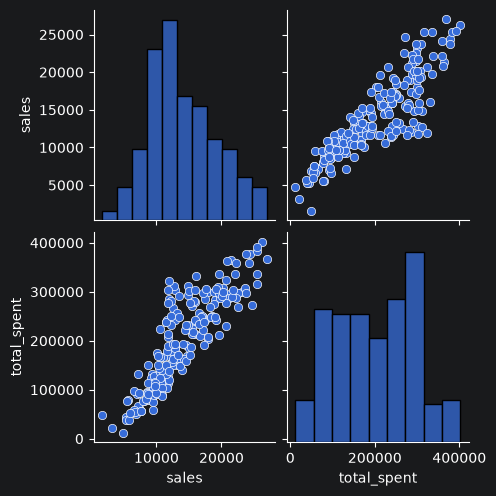

In [76]:
sns.pairplot(df_1[["sales","total_spent"]])

#### Dividing data into training and testing sets

In [82]:
X = df_1[["total_spent"]]
y = df_1["sales"]

In [83]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [84]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['total_spent']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4097
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [111]:
y_pred_train = model.predict(X_train)

mae_train = round(mean_absolute_error(y_train,y_pred_train),2)
mse_train = round(mean_squared_error(y_train,y_pred_train),2)
rmse_train = round(root_mean_squared_error(y_train,y_pred_train),2)
r2_train = round(r2_score(y_train,y_pred_train),2)

print("Training Metrics")
print("Mean Absolute Error     : ",mae_train)
print("Mean Squared Error      : ",mse_train)
print("Root Mean Squared Error : ",rmse_train)
print("R2 score                : ",r2_train)

Training Metrics
Mean Absolute Error     :  1910.51
Mean Squared Error      :  6411806.19
Root Mean Squared Error :  2532.15
R2 score                :  0.75


In [110]:
y_pred_test = model.predict(X_test)

mae_test = round(mean_absolute_error(y_test,y_pred_test),2)
mse_test = round(mean_squared_error(y_test,y_pred_test),2)
rmse_test = round(root_mean_squared_error(y_test,y_pred_test),2)
r2_test = round(r2_score(y_test,y_pred_test),2)

print("Testing Metrics")
print("Mean Absolute Error     : ",mae_test)
print("Mean Squared Error      : ",mse_test)
print("Root Mean Squared Error : ",rmse_test)
print("R2 score                : ",r2_test)

Testing Metrics
Mean Absolute Error     :  2058.86
Mean Squared Error      :  7672702.35
Root Mean Squared Error :  2769.96
R2 score                :  0.76


#### Model Selection

In [113]:
cross_val_score(model,X,y,cv=5)

array([0.75404409, 0.79833075, 0.766472  , 0.74904074, 0.65631766])

In [114]:
import statsmodels. formula. api as smf
mode12=smf.ols("y~X" ,data=df).fit()
mode12.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.754
Model:                            OLS   Adj. R-squared:                  0.753
Method:                 Least Squares   F-statistic:                     607.1
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           3.21e-62
Time:                        17:26:49   Log-Likelihood:                -1855.0
No. Observations:                 200   AIC:                             3714.
Df Residuals:                     198   BIC:                             3721.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4207.1118    438.574      9.593      0.000    3342.236    5071.987
X              0.0490      0.002     24.639      0.000       0.045       0.053
==============================================================================
Omnibus:                        8.587   Durbin-Watson:                   1.984
Prob(Omnibus):                  0.014   Jarque-Bera (JB):                8.682
Skew:                          -0.427   Prob(JB):                       0.0130
Kurtosis:                       3.559   Cond. No.                     5.27e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.27e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

<Axes: xlabel='total_spent', ylabel='sales'>

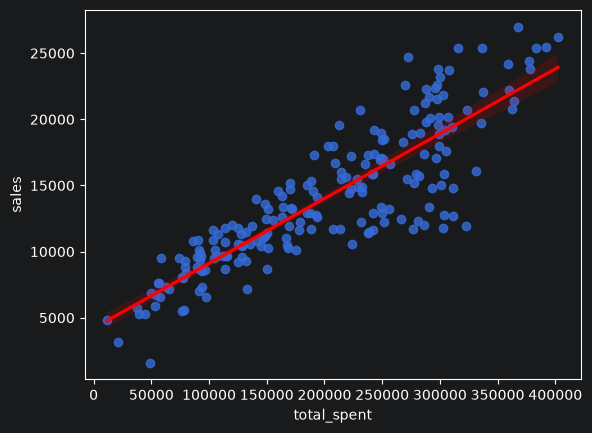

In [156]:
sns.regplot(x=df_1["total_spent"],y=df_1["sales"],line_kws={"color":"red"})

(-10000.0, 10000.0)

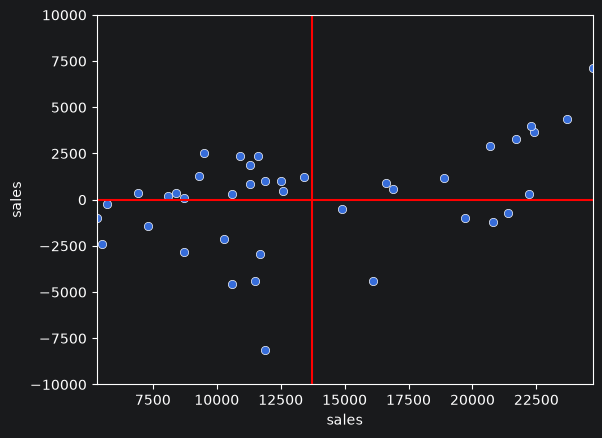

In [146]:
residuals = (y_test - y_pred_test)

plt.axhline(y=0,color="red")
plt.axvline(x=y_test.mean(),color="red")

sns.scatterplot(x=y_test,y=residuals)
plt.xlim(y_test.min(),y_test.max())
plt.ylim(-10000,10000)

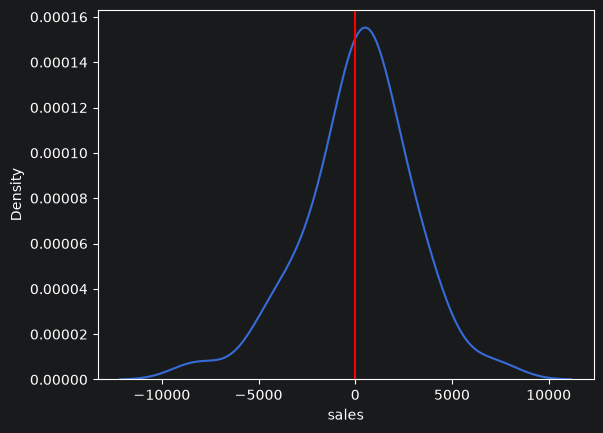

In [158]:
sns.kdeplot(residuals)
plt.axvline(x=0,color="red")